
# Assignment 6


## 1(a) K-Means Clustering on Random Data Points Without Outliers


In [ ]:

import numpy as np
import matplotlib.pyplot as plt


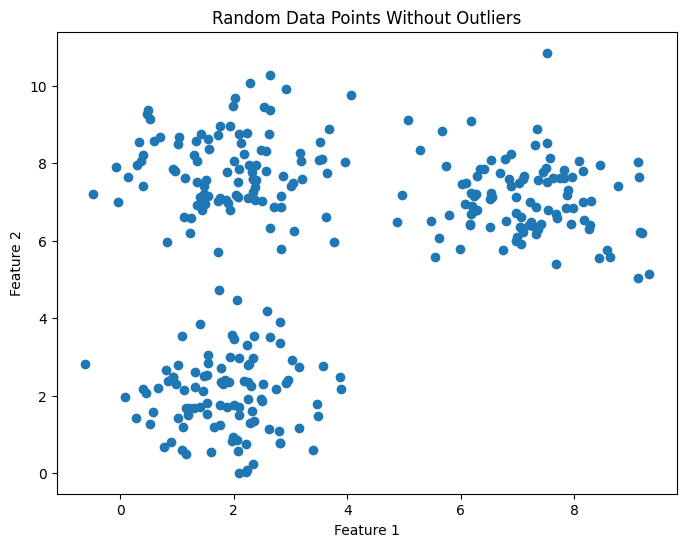

In [ ]:

np.random.seed(42)

cluster1 = np.random.randn(100, 2) + [2, 2]
cluster2 = np.random.randn(100, 2) + [7, 7]
cluster3 = np.random.randn(100, 2) + [2, 8]

X = np.vstack((cluster1, cluster2, cluster3))

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1])
plt.title("Random Data Points Without Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [ ]:

def kmeans(X, k, max_iters=100):
    indices = np.random.choice(len(X), k, replace=False)
    centroids = X[indices].copy()

    for _ in range(max_iters):
        distances = np.sqrt(
            ((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
        )

        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([
            X[labels == i].mean(axis=0)
            if np.any(labels == i)
            else centroids[i]
            for i in range(k)
        ])

        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    distances = np.sqrt(
        ((X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2).sum(axis=2)
    )
    labels = np.argmin(distances, axis=1)

    return labels, centroids


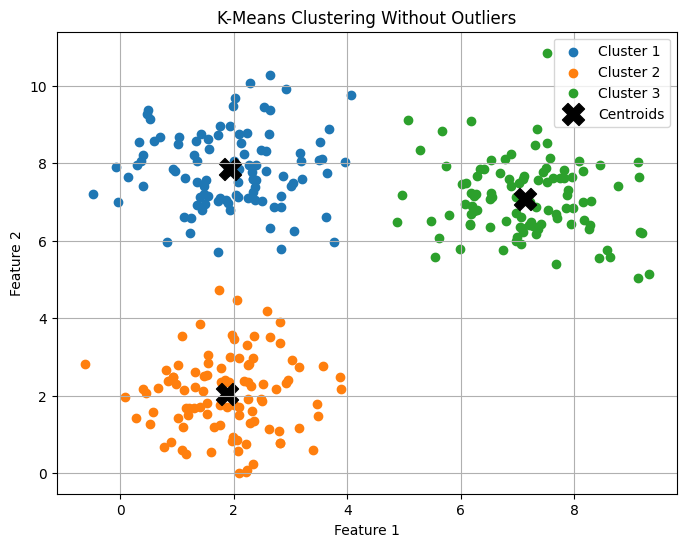

Final Centroids:
[[1.94176113 7.84228769]
 [1.88443575 2.03402232]
 [7.14145021 7.07492727]]


In [ ]:

labels, centroids = kmeans(X, 3)

plt.figure(figsize=(8, 6))

for i in range(3):
    plt.scatter(
        X[labels == i, 0],
        X[labels == i, 1],
        label=f"Cluster {i + 1}"
    )

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title("K-Means Clustering Without Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

print("Final Centroids:")
print(centroids)



## 1(b) K-Means Clustering on Random Data Points With Outliers


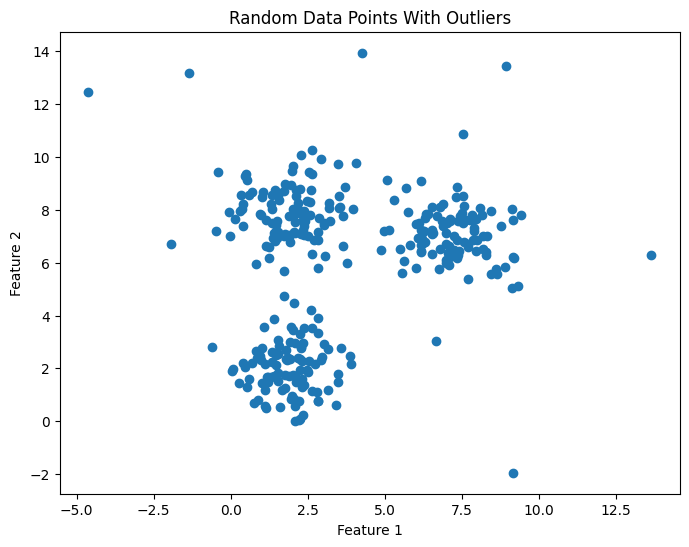

In [ ]:

np.random.seed(42)

cluster1 = np.random.randn(100, 2) + [2, 2]
cluster2 = np.random.randn(100, 2) + [7, 7]
cluster3 = np.random.randn(100, 2) + [2, 8]

outliers = np.random.uniform(low=-5, high=15, size=(15, 2))

X_outliers = np.vstack((cluster1, cluster2, cluster3, outliers))

plt.figure(figsize=(8, 6))
plt.scatter(X_outliers[:, 0], X_outliers[:, 1])
plt.title("Random Data Points With Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [ ]:

labels_outliers, centroids_outliers = kmeans(X_outliers, 3)


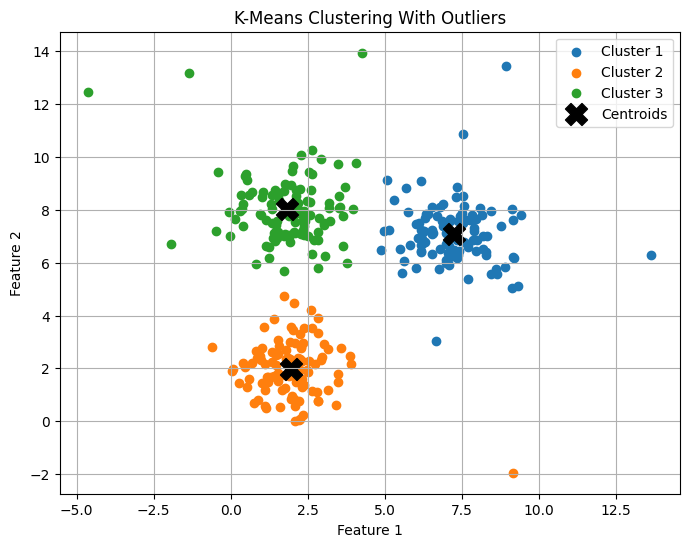

Final Centroids:
[[7.22721008 7.08694611]
 [1.93749342 1.99379346]
 [1.82589676 8.01589111]]


In [ ]:

plt.figure(figsize=(8, 6))

for i in range(3):
    plt.scatter(
        X_outliers[labels_outliers == i, 0],
        X_outliers[labels_outliers == i, 1],
        label=f"Cluster {i + 1}"
    )

plt.scatter(
    centroids_outliers[:, 0],
    centroids_outliers[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title("K-Means Clustering With Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()

print("Final Centroids:")
print(centroids_outliers)



## 1(c) K-Means Clustering on a Tabular Dataset


In [ ]:

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

df.head()


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:

X_tabular = df.drop(columns=["species"]).values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_tabular)

print("Dataset shape:", X_scaled.shape)
print("Number of samples:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])


Dataset shape: (150, 4)
Number of samples: 150
Number of features: 4


In [ ]:

labels_tabular, centroids_tabular = kmeans(X_scaled, 3)

print("Final Centroids:")
print(centroids_tabular)


Final Centroids:
[[ 1.13597027  0.08842168  0.99615451  1.01752612]
 [-0.05021989 -0.88337647  0.34773781  0.2815273 ]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]]


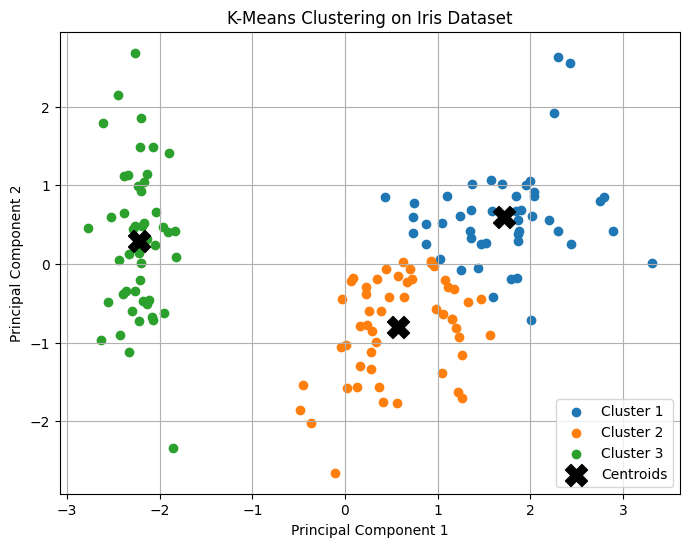

In [ ]:

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

centroids_pca = pca.transform(centroids_tabular)

plt.figure(figsize=(8, 6))

for i in range(3):
    plt.scatter(
        X_pca[labels_tabular == i, 0],
        X_pca[labels_tabular == i, 1],
        label=f"Cluster {i + 1}"
    )

plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Centroids"
)

plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.show()



## 1(d) K-Means Clustering on Image Data Using Pixel Pairs


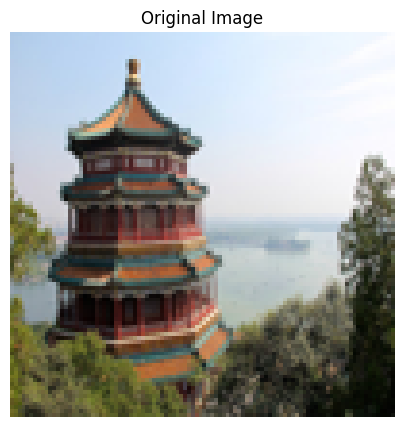

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.datasets import load_sample_image

img_array = load_sample_image("china.jpg")
img = Image.fromarray(img_array).convert("RGB")
img = img.resize((100, 100))

img_array = np.array(img)

plt.figure(figsize=(5, 5))
plt.imshow(img_array)
plt.title("Original Image")
plt.axis("off")
plt.show()


In [ ]:

pixels = img_array.reshape(-1, 3)

pixel_pairs = np.column_stack((
    pixels[:, 0],
    pixels[:, 1]
))

print("Image dimensions:", img_array.shape)
print("Number of pixels:", len(pixels))
print("Pixel pairs shape:", pixel_pairs.shape)


Image dimensions: (100, 100, 3)
Number of pixels: 10000
Pixel pairs shape: (10000, 2)


In [ ]:

labels_image, centroids_image = kmeans(pixel_pairs.astype(float), 3)

print("Final Centroids:")
print(centroids_image)



Final Centroids:
[[120.23956781 109.7928465 ]
 [214.01265551 223.46567997]
 [ 47.77844763  44.57045968]]


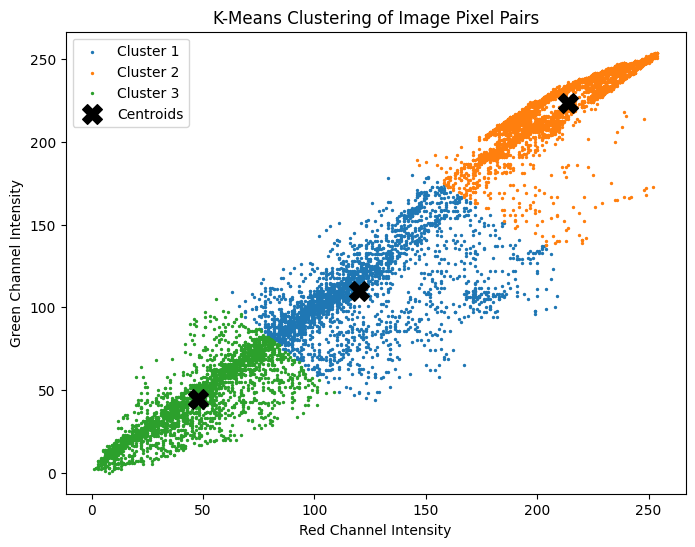

In [ ]:

plt.figure(figsize=(8, 6))

for i in range(3):
    plt.scatter(
        pixel_pairs[labels_image == i, 0],
        pixel_pairs[labels_image == i, 1],
        s=2,
        label=f"Cluster {i + 1}"
    )

plt.scatter(
    centroids_image[:, 0],
    centroids_image[:, 1],
    marker="X",
    s=200,
    color="black",
    label="Centroids"
)

plt.title("K-Means Clustering of Image Pixel Pairs")
plt.xlabel("Red Channel Intensity")
plt.ylabel("Green Channel Intensity")
plt.legend()
plt.show()


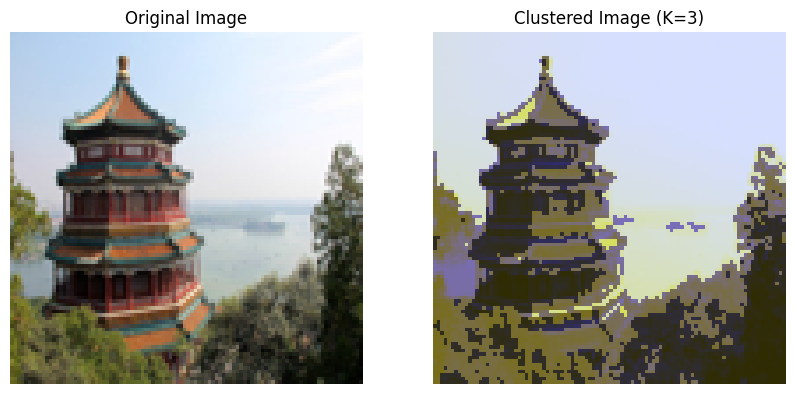

In [ ]:

clustered_pixels = np.zeros_like(pixels)

clustered_pixels[:, 0] = centroids_image[labels_image, 0]
clustered_pixels[:, 1] = centroids_image[labels_image, 1]
clustered_pixels[:, 2] = pixels[:, 2]

clustered_img = clustered_pixels.reshape(img_array.shape).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_array)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clustered_img)
plt.title("Clustered Image (K=3)")
plt.axis("off")

plt.show()



## 2(a) Hierarchical Clustering Using Bottom-Up Approach


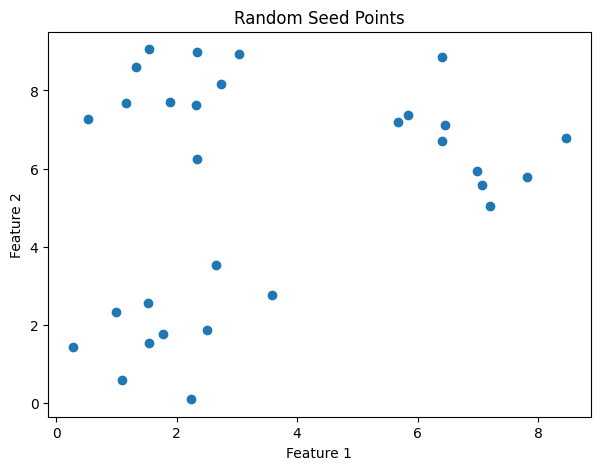

In [ ]:

np.random.seed(42)

X_hier = np.vstack([
    np.random.randn(10, 2) + [2, 2],
    np.random.randn(10, 2) + [7, 7],
    np.random.randn(10, 2) + [2, 8]
])

plt.figure(figsize=(7, 5))
plt.scatter(X_hier[:, 0], X_hier[:, 1])
plt.title("Random Seed Points")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


In [ ]:

def agglomerative_clustering(X, k):
    clusters = [[i] for i in range(len(X))]

    while len(clusters) > k:
        min_dist = float("inf")
        merge_i, merge_j = 0, 1

        for i in range(len(clusters)):
            for j in range(i + 1, len(clusters)):
                for p in clusters[i]:
                    for q in clusters[j]:
                        dist = np.linalg.norm(X[p] - X[q])

                        if dist < min_dist:
                            min_dist = dist
                            merge_i, merge_j = i, j

        clusters[merge_i].extend(clusters[merge_j])
        clusters.pop(merge_j)

    labels = np.zeros(len(X), dtype=int)

    for cluster_id, cluster in enumerate(clusters):
        for point_index in cluster:
            labels[point_index] = cluster_id

    return labels


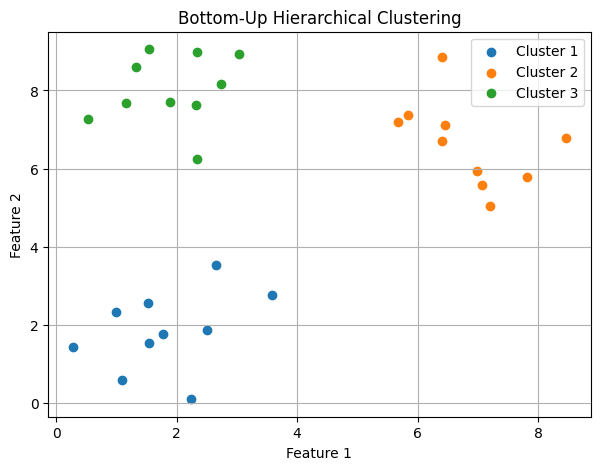

In [ ]:

labels_hier = agglomerative_clustering(X_hier, 3)

plt.figure(figsize=(7, 5))

for i in range(3):
    plt.scatter(
        X_hier[labels_hier == i, 0],
        X_hier[labels_hier == i, 1],
        label=f"Cluster {i + 1}"
    )

plt.title("Bottom-Up Hierarchical Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()



## 2(b) Hierarchical Clustering Using Top-Down Approach


In [ ]:

def divisive_clustering(X, k):
    clusters = [list(range(len(X)))]

    while len(clusters) < k:
        largest_idx = max(
            range(len(clusters)),
            key=lambda i: len(clusters[i])
        )

        cluster = clusters.pop(largest_idx)

        if len(cluster) <= 1:
            clusters.append(cluster)
            break

        points = X[cluster]
        center = points.mean(axis=0)

        distances = np.linalg.norm(points - center, axis=1)

        group1 = [cluster[i] for i in range(len(cluster))
                  if distances[i] <= np.median(distances)]

        group2 = [cluster[i] for i in range(len(cluster))
                  if distances[i] > np.median(distances)]

        if len(group1) == 0 or len(group2) == 0:
            sorted_indices = np.argsort(distances)
            mid = len(cluster) // 2

            group1 = [cluster[i] for i in sorted_indices[:mid]]
            group2 = [cluster[i] for i in sorted_indices[mid:]]

        clusters.extend([group1, group2])

    labels = np.zeros(len(X), dtype=int)

    for cluster_id, cluster in enumerate(clusters):
        for point_index in cluster:
            labels[point_index] = cluster_id

    return labels


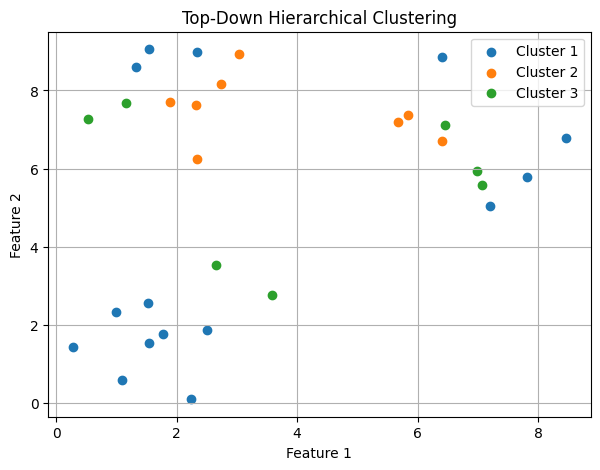

In [ ]:

labels_div = divisive_clustering(X_hier, 3)

plt.figure(figsize=(7, 5))

for i in range(3):
    plt.scatter(
        X_hier[labels_div == i, 0],
        X_hier[labels_div == i, 1],
        label=f"Cluster {i + 1}"
    )

plt.title("Top-Down Hierarchical Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(True)
plt.show()



## 2(c) Hierarchical Clustering on Tabular Dataset


In [ ]:

import pandas as pd
from sklearn.preprocessing import StandardScaler

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

X_tabular = df.drop(columns=["species"]).values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_tabular)

print("Dataset Shape:", X_scaled.shape)


Dataset Shape: (150, 4)


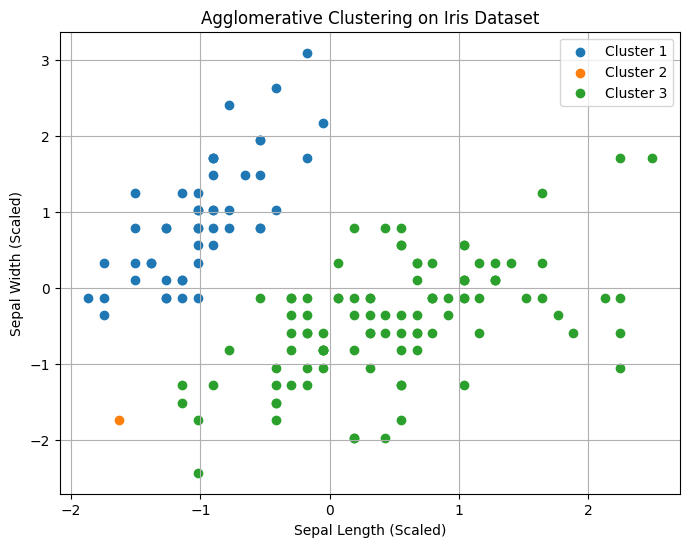

In [ ]:

labels_agg = agglomerative_clustering(X_scaled, 3)

plt.figure(figsize=(8, 6))

for i in range(3):
    plt.scatter(
        X_scaled[labels_agg == i, 0],
        X_scaled[labels_agg == i, 1],
        label=f"Cluster {i + 1}"
    )

plt.title("Agglomerative Clustering on Iris Dataset")
plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")
plt.legend()
plt.grid(True)
plt.show()


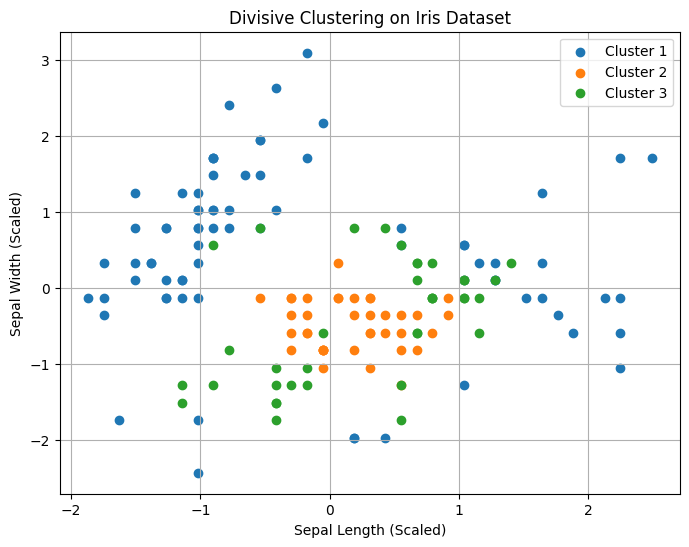

In [ ]:

labels_div_tabular = divisive_clustering(X_scaled, 3)

plt.figure(figsize=(8, 6))

for i in range(3):
    plt.scatter(
        X_scaled[labels_div_tabular == i, 0],
        X_scaled[labels_div_tabular == i, 1],
        label=f"Cluster {i + 1}"
    )

plt.title("Divisive Clustering on Iris Dataset")
plt.xlabel("Sepal Length (Scaled)")
plt.ylabel("Sepal Width (Scaled)")
plt.legend()
plt.grid(True)
plt.show()



## 2(d) Hierarchical Clustering on Image Data Using Pixel Pairs


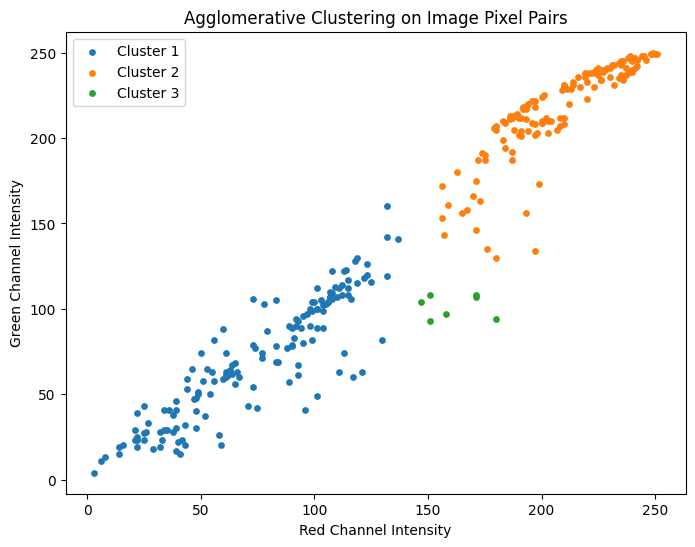

In [ ]:
np.random.seed(42)

sample_indices = np.random.choice(len(pixel_pairs), 300, replace=False)
sample_pixels = pixel_pairs[sample_indices].astype(float)

labels_image_agg = agglomerative_clustering(sample_pixels, 3)

plt.figure(figsize=(8, 6))

for i in range(3):
    plt.scatter(
        sample_pixels[labels_image_agg == i, 0],
        sample_pixels[labels_image_agg == i, 1],
        s=15,
        label=f"Cluster {i + 1}"
    )

plt.title("Agglomerative Clustering on Image Pixel Pairs")
plt.xlabel("Red Channel Intensity")
plt.ylabel("Green Channel Intensity")
plt.legend()
plt.show()


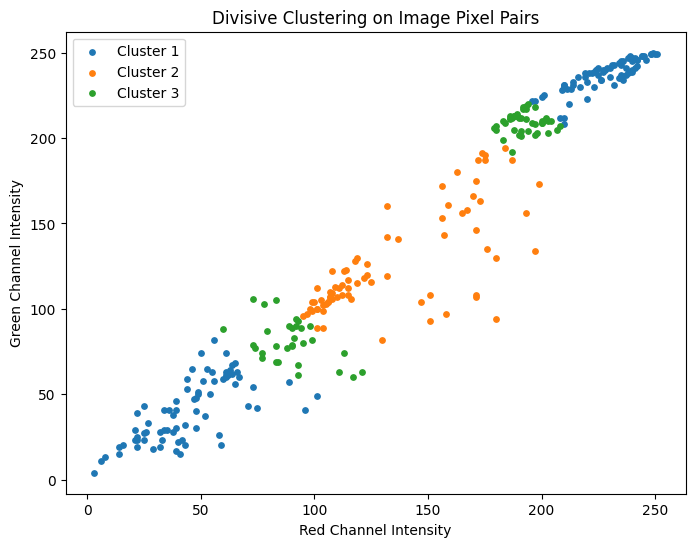

In [ ]:

labels_image_div = divisive_clustering(sample_pixels, 3)

plt.figure(figsize=(8, 6))

for i in range(3):
    plt.scatter(
        sample_pixels[labels_image_div == i, 0],
        sample_pixels[labels_image_div == i, 1],
        s=15,
        label=f"Cluster {i + 1}"
    )

plt.title("Divisive Clustering on Image Pixel Pairs")
plt.xlabel("Red Channel Intensity")
plt.ylabel("Green Channel Intensity")
plt.legend()
plt.show()
